# Thermal phase curves with heat redistribution: `insolation_model="naive_redist"`

`naive_redist` keeps the point-source (`naive`) insolation, so its **reflected** phase curve is exactly that of `naive`, but redistributes the absorbed heat with the toy model of Kreidberg & Loeb (2016, eq. 1):

$$
\sigma T^4(z) =
\begin{cases}
(1-A_B)\,S\left[\dfrac{F}{2} + (1-2F)\cos z\right], & \text{dayside } (z \le 90^\circ)\\[6pt]
(1-A_B)\,S\,\dfrac{F}{2}, & \text{nightside}
\end{cases}
$$

$z$ is the zenith angle (angular distance from the substellar point), $S = \sigma T_\mathrm{eff}^4 (r_2/R)^2$ the substellar insolation and $F \in [0, 0.5]$ the heat redistribution parameter: the nightside re-radiates the fraction $F$ of the absorbed power. $F = 0$ is the bare rock (identical to `naive`), $F = 0.5$ an isothermal planet. The **thermal** phase curve is SPIDERMAN's analytic Louden model (`Louden_PhaseCurve`), which evaluates exactly this map.

In [1]:
import numpy as np
import pandas as pd
import contextlib, io
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from dataclasses import replace
from scipy.optimize import minimize, minimize_scalar
from joblib import Parallel, delayed
from joblib.externals.loky import get_reusable_executor  # to recycle SPIDERMAN workers between sweeps
with contextlib.redirect_stdout(io.StringIO()):          # mute "no spidermanrc file detected"
    import fspiderman as sp
from hyperillumination_utils import *
from hyperillumination_phasecurve_utils import *
from astro_utils import *
import batman_utils
from simple_bias_analysis import binned
from HItargets_utils import hi_planets_by_name, filter_loc, filter_lambda, instruments

In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
K2_141b = hi_planets_by_name("K2-141 b")
period, incl, ecc, w, r1, r2, R, T2_eff, a_AU = K2_141b.args

fp = 142e-6                                 # planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm

u = [0.15, 0.08]                            # Band-integrated (MIR) quadratic stellar limb darkening coefficients [u1, u2] (placeholders from grey Eddington atmosphere, not from K2-141 data)
u_B = 0.6                                   # Bolometric linear stellar limb darkening coefficient (placeholder, from Sadh_Gavassino_2026)

# Albedo assumptions (see test_ThermalPhaseCurve.ipynb)
Ag = 0.28                                   # Geometric albedo in the optical from Zieba 2022
A_B = 3/2 * Ag                              # 0.42, grey Lambertian reflectance. PROBABLY UNPHYSICAL!
A = ConstantBandAlbedo(.1)(A_B)             # band-integrated albedo in the MIR, only for the full (reflected + thermal) phase curve, as in test_FullPhaseCurve.ipynb

# Filter to be used
Instrument = "MIRI/LRS"
lambda_range = filter_lambda(Instrument)
filter_path = filter_loc(Instrument)

In [3]:
F_values = np.array([0., 0.01, 0.05, 0.25, 0.5])   # heat redistribution values of Kreidberg & Loeb 2016, Fig. 1

# F is ordered -> one-hue (blue) ramp, light -> dark. The reference models keep a fixed colour throughout the notebook.
F_COLORS = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281"]
C_REDIST, C_HI, C_NAIVE = "#2a78d6", "#eb6834", "#52514e"   # a single naive_redist curve (blue), hyperillum (orange), naive (grey, dashed)
INK, INK_2, AXIS = "#0b0b0b", "#52514e", "#c3c2b7"
SEQ_BLUE = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"])

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "savefig.facecolor": "#fcfcfb",
    "axes.edgecolor": AXIS, "axes.linewidth": 0.8, "axes.labelcolor": INK, "axes.titlecolor": INK,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6, "grid.linestyle": "-",
    "xtick.color": INK_2, "ytick.color": INK_2, "text.color": INK,
    "lines.linewidth": 1.5, "lines.solid_capstyle": "round", "lines.solid_joinstyle": "round",
    "legend.frameon": False, "font.size": 11, "axes.titlesize": 12,
})

F_label = lambda F: f"$F$ = {F:g}"
phase = lambda t: t / period   # orbital phase: 0 = transit, 0.5 = occultation
t = np.linspace(0., period, 1000, endpoint=False)
PHASE_LABEL = "Orbital phase (0 = transit, 0.5 = occultation)"
FLUX_LABEL = "Planet flux $F_p/F_s$ [ppm]"

def sqrt_F_axis(ax, F_max=0.5, ticks=(0., 0.01, 0.05, 0.1, 0.25, 0.5)):
    # most of the change happens at small F -> square-root scaled F axis
    ax.set_xscale("function", functions=(np.sqrt, np.square))
    ax.set_xticks(ticks, [f"{f:g}" for f in ticks])
    ax.set_xlim(0., F_max)
    ax.set_xlabel("Heat redistribution $F$ (square-root scale)")

def pmap(fn, items):
    # process-parallel map over independent SPIDERMAN evaluations (the C extension holds the GIL, so threads give no speedup); workers are recycled afterwards to release allocator memory
    out = Parallel(n_jobs=-1, backend="loky")(delayed(fn)(*item) for item in items)
    get_reusable_executor().shutdown(wait=True)
    return out

## 1. Temperature profile $T(z)$ (Kreidberg & Loeb 2016, eq. 1)

`surface_temperature(z, planet, "naive_redist", A_B=..., F=...)` evaluates eq. 1 directly. The panels show K2-141b and TOI-2431 b with the same settings ($A_B = 0.42$, $u_B = 0.6$), each with `hyperillum` and `naive` for reference. The shaded band is the planet's hyperillumination penumbra. The temperature is continuous at the terminator for every $F$; only its slope jumps there.

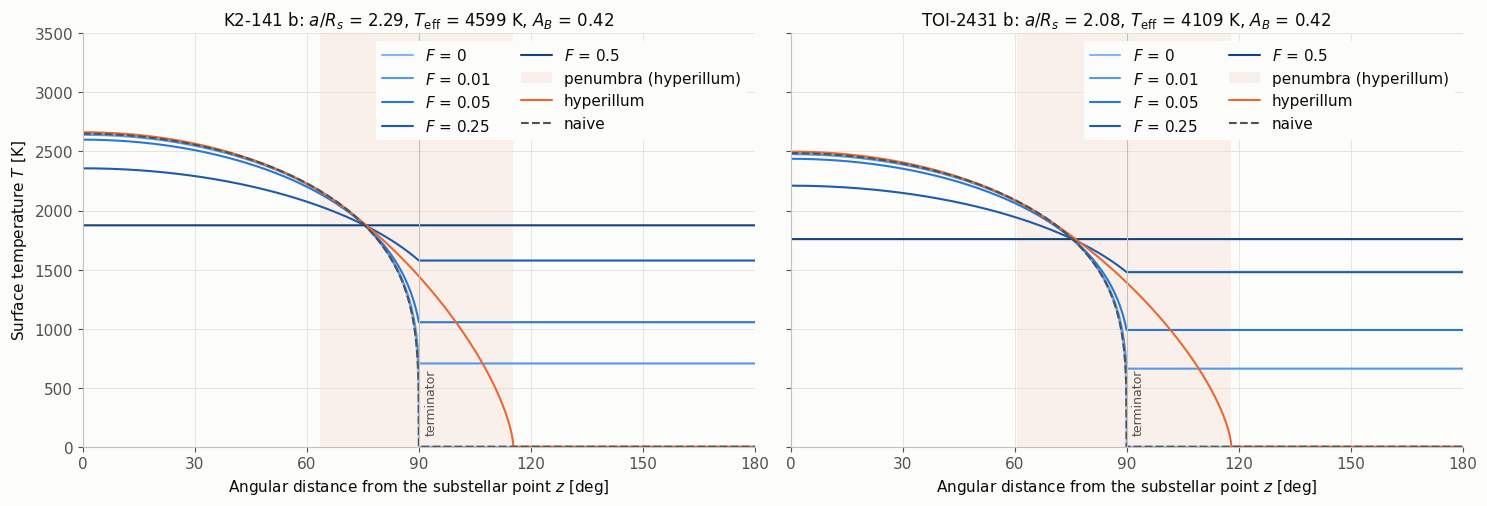

,K2-141 b T_sub [K],K2-141 b T_night [K],TOI-2431 b T_sub [K],TOI-2431 b T_night [K]
F,,,,
0.00,2651.0,0.0,2485.8,0.0
0.01,2641.0,704.9,2476.4,661.0
0.05,2599.9,1054.1,2437.8,988.4
0.25,2357.1,1576.3,2210.2,1478.1
0.50,1874.6,1874.6,1757.7,1757.7


In [4]:
z = np.linspace(0., np.pi, 2001)   # angular distance from the substellar point (Kreidberg & Loeb's zenith angle)
z_deg = np.degrees(z)
TOI_2431b = hi_planets_by_name("TOI-2431 b")
planets = [K2_141b, TOI_2431b]

fig, axs = plt.subplots(1, 2, figsize=(15, 5.2), sharey=True)
for ax, pl in zip(axs, planets):
    for F, col in zip(F_values, F_COLORS):
        ax.plot(z_deg, surface_temperature(z, pl, "naive_redist", A_B=A_B, F=F), color=col, label=F_label(F))
    ax.axvspan(pl.terminator_penumbra(unit="deg"), pl.terminator_nightside(unit="deg"), color=C_HI, alpha=0.08, lw=0, label="penumbra (hyperillum)")
    ax.plot(z_deg, surface_temperature(z, pl, "hyperillum", u_B=u_B, A_B=A_B), color=C_HI, label="hyperillum")
    ax.plot(z_deg, surface_temperature(z, pl, "naive", A_B=A_B), color=C_NAIVE, ls="--", label="naive")
    ax.axvline(90., color=AXIS, lw=0.8)
    ax.text(91.5, 100., "terminator", rotation=90, color=INK_2, fontsize=9, va="bottom")
    ax.set(xlabel="Angular distance from the substellar point $z$ [deg]", xlim=(0, 180), ylim=(0, 3500),
           title=f"{pl.name}: $a/R_s$ = {pl.R / pl.r2:.2f}, $T_\\mathrm{{eff}}$ = {pl.T2_eff:.0f} K, $A_B$ = {A_B:.2f}")
    ax.set_xticks(np.arange(0, 181, 30))
    ax.legend(loc="upper right", ncol=2, frameon=True, facecolor="#fcfcfb", edgecolor="none", framealpha=1.)
axs[0].set_ylabel("Surface temperature $T$ [K]")
plt.tight_layout()
plt.show()

rows = [{"F": F, **{f"{pl.name} {name} [K]": float(surface_temperature(z_, pl, "naive_redist", A_B=A_B, F=F))
                    for pl in planets for name, z_ in (("T_sub", 0.), ("T_night", np.pi))}} for F in F_values]
pd.DataFrame(rows).set_index("F").round(1)

**Energy budget.** Integrating $\sigma T^4$ over the sphere must return the absorbed power $(1-A_B)\,S\,\pi r_1^2$ for every $F$, and the nightside must emit the fraction $F$ of it.

In [5]:
n_lo_e, n_la_e = 2000, 1000
lo_e = (np.arange(n_lo_e) + 0.5) / n_lo_e * 2 * np.pi - np.pi   # cell centres [rad]
la_e = (np.arange(n_la_e) + 0.5) / n_la_e * np.pi - np.pi / 2
LO_e, LA_e = np.meshgrid(lo_e, la_e)
dA = np.cos(LA_e) * (2 * np.pi / n_lo_e) * (np.pi / n_la_e)     # area element per unit r1^2
z_e = np.arccos(np.clip(np.cos(LA_e) * np.cos(LO_e), -1., 1.))
nightside = np.abs(LO_e) > np.pi / 2

S = float(naive_insolation(0., K2_141b))   # substellar insolation [W/m^2]
absorbed = (1 - A_B) * S * np.pi           # per unit r1^2

rows = []
for F in F_values:
    emitted = sigma * surface_temperature(z_e, K2_141b, "naive_redist", A_B=A_B, F=F)**4 * dA
    rows.append({"F": F, "emitted / absorbed": emitted.sum() / absorbed, "nightside share of the emission": emitted[nightside].sum() / emitted.sum()})
pd.DataFrame(rows).set_index("F").round(5)

,emitted / absorbed,nightside share of the emission
F,,
0.00,1.0,0.00
0.01,1.0,0.01
0.05,1.0,0.05
0.25,1.0,0.25
0.50,1.0,0.50


## 2. Temperature maps

`custom_temperature_grid(..., insolation_model="naive_redist", F=F)` gives the same map on the (longitude, latitude) grid. The last panel shows `hyperillum` for comparison. All panels share one colour scale, and the white lines mark the terminator.

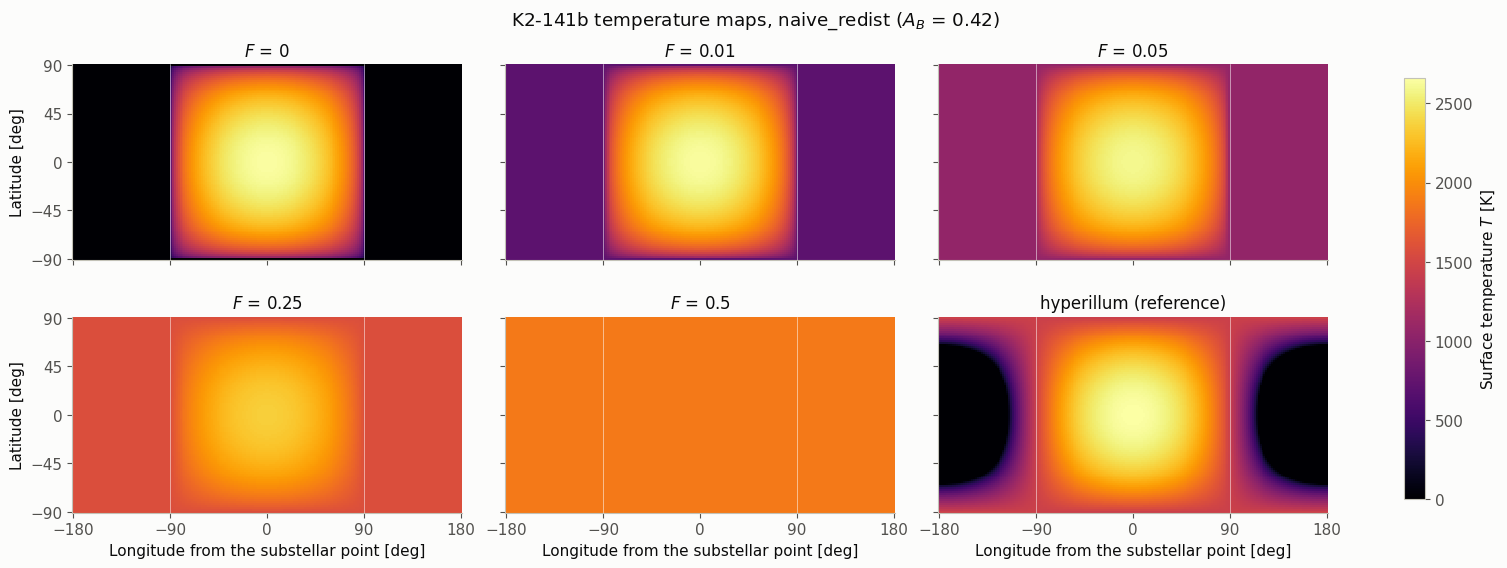

In [6]:
maps = {F: custom_temperature_grid(K2_141b, insolation_model="naive_redist", F=F, A_B=A_B)[2] for F in F_values}
lo, la, T_hi = custom_temperature_grid(K2_141b, insolation_model="hyperillum", u_B=u_B, A_B=A_B)
T_max = max([T_hi.max()] + [Tg.max() for Tg in maps.values()])

fig, axs = plt.subplots(2, 3, figsize=(15, 5.6), sharex=True, sharey=True, constrained_layout=True)
panels = [(F_label(F), maps[F]) for F in F_values] + [("hyperillum (reference)", T_hi)]
for ax, (title, Tg) in zip(axs.ravel(), panels):
    im = ax.pcolormesh(lo, la, Tg, cmap="inferno", vmin=0., vmax=T_max, shading="auto", rasterized=True)
    for x in (-90., 90.):
        ax.axvline(x, color="w", lw=0.6, alpha=0.6)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.grid(False)
    ax.set_xticks(np.arange(-180, 181, 90)); ax.set_yticks(np.arange(-90, 91, 45))
for ax in axs[-1]: ax.set_xlabel("Longitude from the substellar point [deg]")
for ax in axs[:, 0]: ax.set_ylabel("Latitude [deg]")
fig.colorbar(im, ax=axs, label="Surface temperature $T$ [K]", shrink=0.85)
fig.suptitle(f"K2-141b temperature maps, naive_redist ($A_B$ = {A_B:.2f})")
plt.show()

The same maps as the observer sees them at quadrature (phase 0.25), drawn with `plot_insolmap`, with the terminator in grey. Top row: temperature. Bottom row: re-radiated flux ($\propto \sigma T^4$), normalised to the substellar point, i.e. `unit="flux"`. With redistribution the nightside glows at $(F/2)/(1 - 3F/2)$ of the substellar flux.

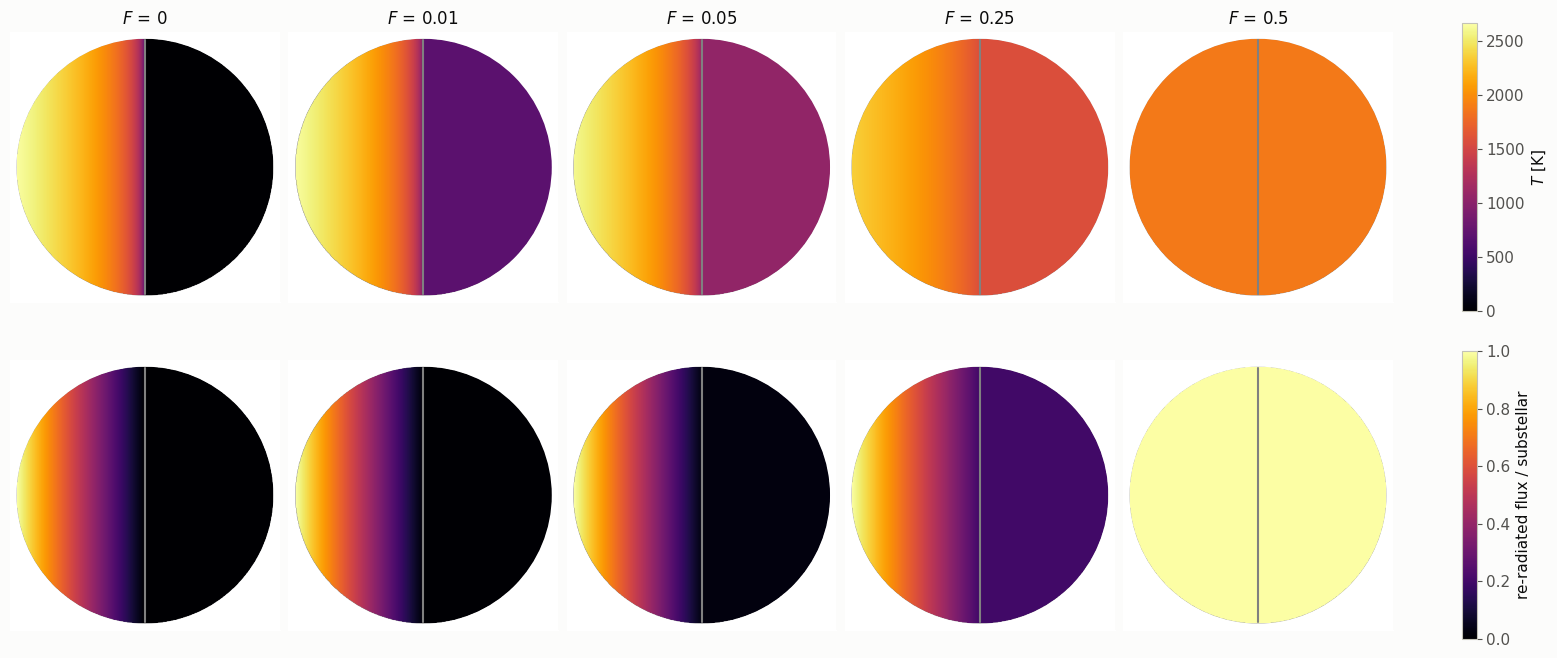

In [7]:
fig, axs = plt.subplots(2, len(F_values), figsize=(3.1 * len(F_values), 6.6), constrained_layout=True)
for j, F in enumerate(F_values):
    plot_insolmap(0.25, K2_141b, A_B=A_B, insolation_model="naive_redist", F=F, unit="temperature", min_temp=0., max_temp=T_max,
                  n_grid=400, ax=axs[0, j], theme="white", show_cax=False, terminator=True)
    plot_insolmap(0.25, K2_141b, insolation_model="naive_redist", F=F, unit="flux", min_temp=0., max_temp=1.,
                  n_grid=400, ax=axs[1, j], theme="white", show_cax=False, terminator=True)
    axs[0, j].set_title(F_label(F))
fig.colorbar(axs[0, -1].images[0], ax=axs[0, :], label="$T$ [K]", shrink=0.9)
fig.colorbar(axs[1, -1].images[0], ax=axs[1, :], label="re-radiated flux / substellar", shrink=0.9)
plt.show()

## 3. Thermal phase curves for a range of $F$

`thermal_PhaseCurve(..., insolation_model="naive_redist", F=F)` dispatches to `Louden_PhaseCurve`. The curves below are the planet's thermal light curve: phase variation plus occultation, without the transit. Redistribution lowers the dayside flux and raises the nightside flux, so the phase amplitude shrinks until the curve is flat at $F = 0.5$.

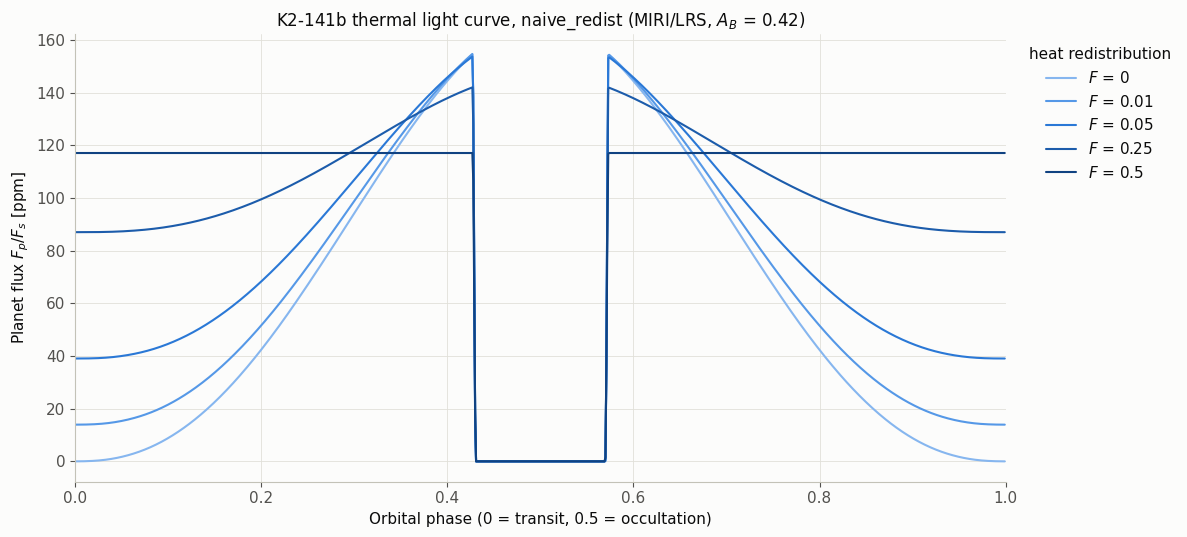

,T_night (eq. 1) [K],occultation depth [ppm],dayside T_bright [K],nightside flux [ppm],peak-to-trough [ppm]
model,,,,,
"naive_redist, F = 0",0.0,167.8,2358.4,0.0,167.8
"naive_redist, F = 0.01",704.9,167.1,2351.9,13.9,153.1
"naive_redist, F = 0.05",1054.1,164.2,2324.7,39.1,125.1
"naive_redist, F = 0.25",1576.3,147.4,2166.4,87.0,60.4
"naive_redist, F = 0.5",1874.6,117.1,1875.4,117.1,0.0
hyperillum,NaN,168.8,2367.7,3.3,165.4
naive,NaN,167.8,2358.5,0.0,167.8


In [8]:
kw = dict(t=t, u=u, u_B=u_B, filter_path=filter_path, A_B=A_B, include_transit=False)

def thermal_curves(model, F):
    # thermal light curve (with occultation) and pure phase variation (without) [ppm], plus the occultation depth [ppm]
    _, lc, fp_, _ = thermal_PhaseCurve(K2_141b, lambda_range, insolation_model=model, F=F, **kw)
    _, pv, _, _ = thermal_PhaseCurve(K2_141b, lambda_range, insolation_model=model, F=F, include_occultation=False, **kw)
    return lc * 1e6, pv * 1e6, fp_

runs = [("naive_redist", F) for F in F_values] + [("hyperillum", None), ("naive", None)]
out = pmap(thermal_curves, runs)
redist = {F: o for (m, F), o in zip(runs, out) if m == "naive_redist"}   # F -> (light curve, phase variation, depth)
ref = {m: o for (m, F), o in zip(runs, out) if m != "naive_redist"}      # reference models

fig, ax = plt.subplots(figsize=(12, 5.5))
for F, col in zip(F_values, F_COLORS):
    ax.plot(phase(t), redist[F][0], color=col, label=F_label(F))
ax.set(xlabel=PHASE_LABEL, ylabel=FLUX_LABEL, xlim=(0, 1), title=f"K2-141b thermal light curve, naive_redist ({Instrument}, $A_B$ = {A_B:.2f})")
ax.legend(title="heat redistribution", loc="upper left", bbox_to_anchor=(1.01, 1.))
plt.tight_layout()
plt.show()

def observables(lc, pv, fp_):
    return {"occultation depth [ppm]": fp_,
            "dayside T_bright [K]": T_bright(fp_, K2_141b, lambda_range, filter_path=filter_path),
            "nightside flux [ppm]": pv[0],        # t = 0: transit, the nightside faces the observer
            "peak-to-trough [ppm]": np.ptp(pv)}

rows = [{"model": f"naive_redist, F = {F:g}", "T_night (eq. 1) [K]": float(surface_temperature(np.pi, K2_141b, "naive_redist", A_B=A_B, F=F)), **observables(*redist[F])} for F in F_values]
rows += [{"model": m, **observables(*ref[m])} for m in ("hyperillum", "naive")]
pd.DataFrame(rows).set_index("model").round(1)

The full phase curve from `full_PhaseCurve(..., insolation_model="naive_redist", F=F)`, with the transit and the reflected light (band albedo $A = 0.1$). The reflected part is that of `naive` and does not depend on $F$.

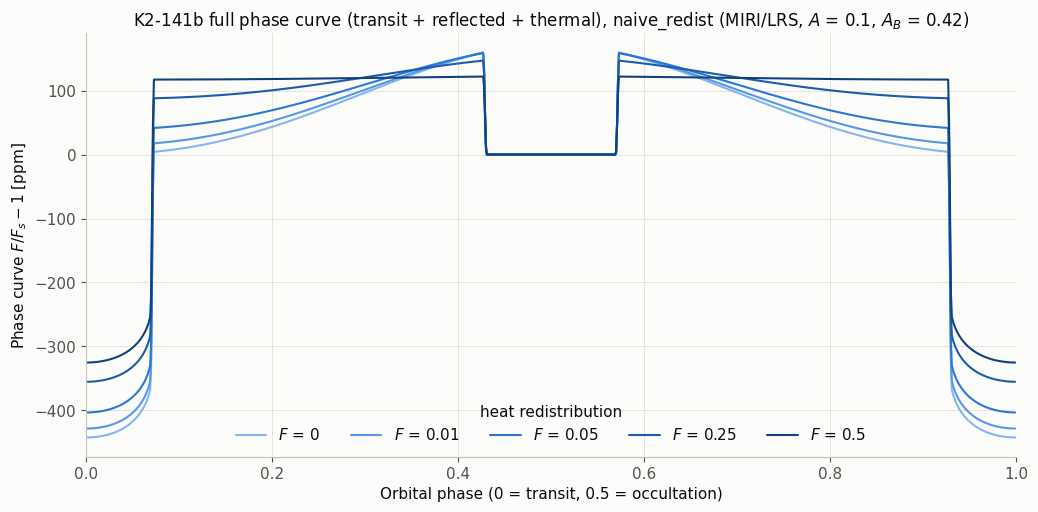

,full occultation depth [ppm],thermal occultation depth [ppm]
F,,
0.00,173.10,167.79
0.01,172.39,167.08
0.05,169.49,164.18
0.25,152.67,147.40
0.50,122.35,117.09


In [9]:
def full_curve(F):
    _, fc, fp_ = full_PhaseCurve(K2_141b, lambda_range, t=t, u=u, u_B=u_B, A=A, A_B=A_B, filter_path=filter_path, insolation_model="naive_redist", F=F)
    return (fc - 1.) * 1e6, fp_

full = dict(zip(F_values, pmap(full_curve, [(F,) for F in F_values])))

fig, ax = plt.subplots(figsize=(12, 5.5))
for F, col in zip(F_values, F_COLORS):
    ax.plot(phase(t), full[F][0], color=col, label=F_label(F))
ax.set(xlabel=PHASE_LABEL, ylabel="Phase curve $F/F_s - 1$ [ppm]", xlim=(0, 1),
       title=f"K2-141b full phase curve (transit + reflected + thermal), naive_redist ({Instrument}, $A$ = {A:g}, $A_B$ = {A_B:.2f})")
ax.legend(title="heat redistribution", loc="lower center", ncol=5)
plt.show()

pd.DataFrame({"F": F_values, "full occultation depth [ppm]": [full[F][1] for F in F_values],
              "thermal occultation depth [ppm]": [redist[F][2] for F in F_values]}).set_index("F").round(2)

## 4. Consistency check: `naive_redist` with $F = 0$ vs `naive`

With $F = 0$, eq. 1 is exactly the `naive` temperature map, and the reflected light is identical by construction. The two thermal curves still differ slightly, because they come from different SPIDERMAN paths. `naive` interpolates a $200\times100$ `direct_T` grid (bicubic, with a 100 K nightside floor), while `naive_redist` evaluates the map analytically (Louden). Both use `N_LAYERS = 80`.

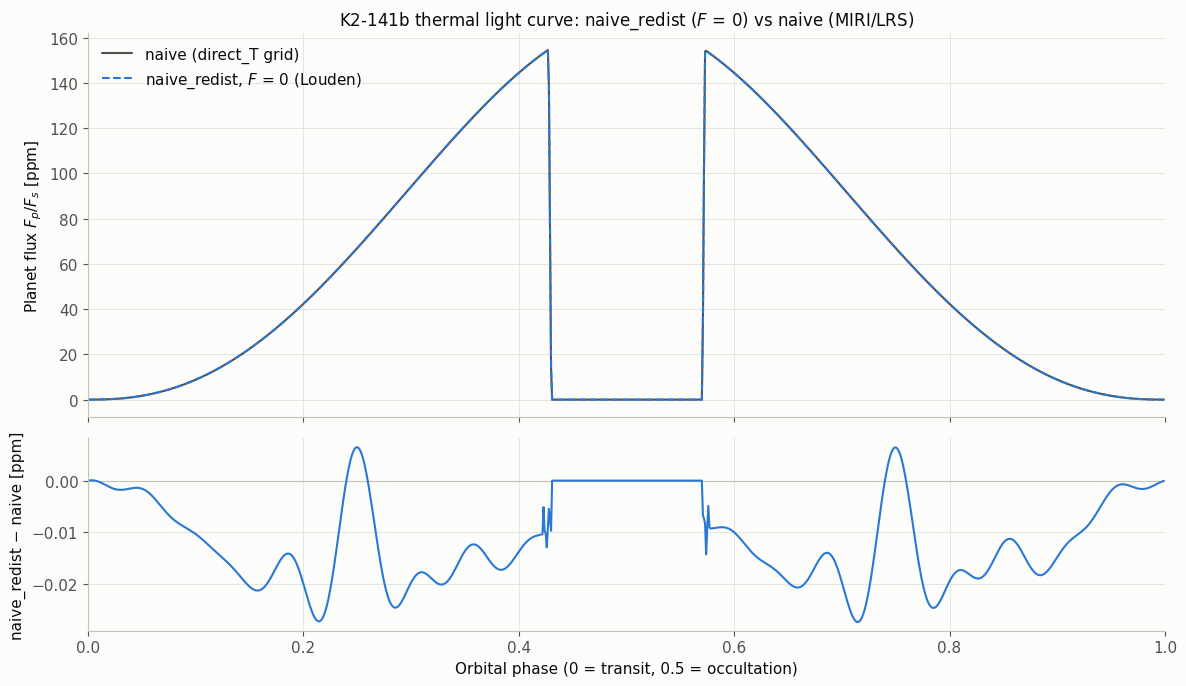

temperature maps identical:     True
reflected phase curves identical: True
thermal light curves: max |diff| = 0.0273 ppm, rms = 0.0138 ppm
occultation depth: naive_redist (F=0) 167.786 ppm, naive 167.787 ppm


In [10]:
lc_n, lc_0 = ref["naive"][0], redist[0.][0]

fig, (ax, axr) = plt.subplots(2, 1, figsize=(12, 7), sharex=True, gridspec_kw=dict(height_ratios=[2, 1]))
ax.plot(phase(t), lc_n, color=C_NAIVE, label="naive (direct_T grid)")
ax.plot(phase(t), lc_0, color=C_REDIST, ls="--", label="naive_redist, $F$ = 0 (Louden)")
ax.set(ylabel=FLUX_LABEL, title=f"K2-141b thermal light curve: naive_redist ($F$ = 0) vs naive ({Instrument})")
ax.legend(loc="upper left")
axr.axhline(0., color=AXIS, lw=0.8)
axr.plot(phase(t), lc_0 - lc_n, color=C_REDIST)
axr.set(xlabel=PHASE_LABEL, ylabel="naive_redist − naive [ppm]", xlim=(0, 1))
plt.tight_layout()
plt.show()

_, refl_n, _ = reflected_PhaseCurve(K2_141b, t=t, u=u, A=A, insolation_model="naive")
_, refl_r, _ = reflected_PhaseCurve(K2_141b, t=t, u=u, A=A, insolation_model="naive_redist")
print(f"temperature maps identical:     {np.array_equal(maps[0.], custom_temperature_grid(K2_141b, insolation_model='naive', A_B=A_B)[2])}")
print(f"reflected phase curves identical: {np.array_equal(refl_n, refl_r)}")
print(f"thermal light curves: max |diff| = {np.abs(lc_0 - lc_n).max():.4f} ppm, rms = {np.sqrt(np.mean((lc_0 - lc_n)**2)):.4f} ppm")
print(f"occultation depth: naive_redist (F=0) {redist[0.][2]:.3f} ppm, naive {ref['naive'][2]:.3f} ppm")

## 5. `naive_redist` vs `hyperillum`, mean subtracted

In a fit the baseline is a free offset, so only the *shape* of a curve matters. Each curve below has its own mean subtracted. The bottom panel shows what a fit would have to absorb: the difference between `naive_redist` and `hyperillum` ($A_B = 0.42$ for both). This section uses small redistributions, $F = 0$ to $0.02$, the range where the fit in 6.4 ends up.

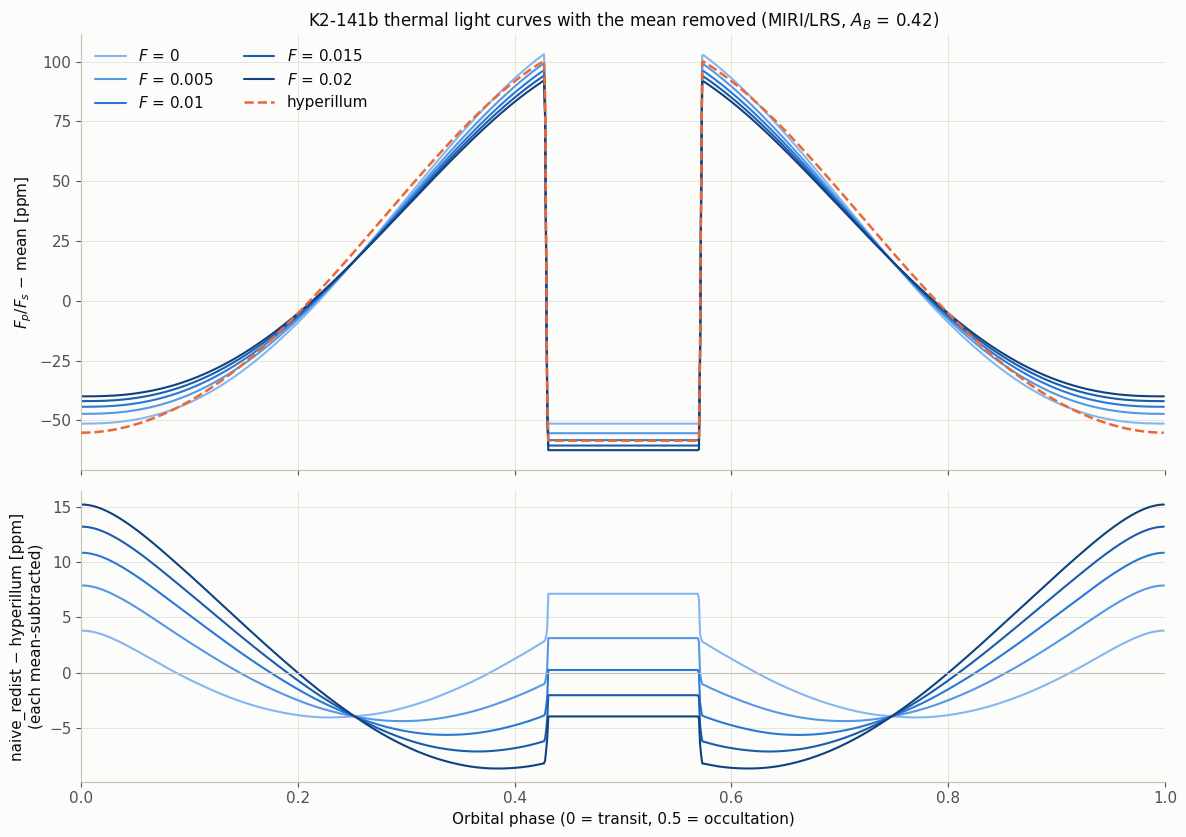

,rms [ppm],max |diff| [ppm]
F,,
0.000,3.68,7.13
0.005,3.84,7.88
0.010,5.15,10.84
0.015,6.53,13.20
0.020,7.81,15.20


In [11]:
F_small = np.array([0., 0.005, 0.01, 0.015, 0.02])   # small F, the range the degeneracy fit in 6.4 ends up in
small = dict(zip(F_small, pmap(thermal_curves, [("naive_redist", F) for F in F_small])))   # F -> (light curve, phase variation, depth)
lc_hi = ref["hyperillum"][0]
d_hi = lc_hi - lc_hi.mean()

fig, (ax, axr) = plt.subplots(2, 1, figsize=(12, 8.5), sharex=True, gridspec_kw=dict(height_ratios=[3, 2]))
rows = []
for F, col in zip(F_small, F_COLORS):   # the ramp spans F_small here, not F_values
    d_F = small[F][0] - small[F][0].mean()
    ax.plot(phase(t), d_F, color=col, label=F_label(F))
    axr.plot(phase(t), d_F - d_hi, color=col, label=F_label(F))
    rows.append({"F": F, "rms [ppm]": np.sqrt(np.mean((d_F - d_hi)**2)), "max |diff| [ppm]": np.abs(d_F - d_hi).max()})
ax.plot(phase(t), d_hi, color=C_HI, lw=1.8, ls="--", label="hyperillum", zorder=5)
ax.set(ylabel="$F_p/F_s$ − mean [ppm]", title=f"K2-141b thermal light curves with the mean removed ({Instrument}, $A_B$ = {A_B:.2f})")
ax.legend(loc="upper left", ncol=2)
axr.axhline(0., color=AXIS, lw=0.8)
axr.set(xlabel=PHASE_LABEL, ylabel="naive_redist − hyperillum [ppm]\n(each mean-subtracted)", xlim=(0, 1))
plt.tight_layout()
plt.show()

pd.DataFrame(rows).set_index("F").round(2)

## 6. Further diagnostics

### 6.1 Observables as a function of $F$

These are the MIRI/LRS occultation depth, peak-to-trough phase amplitude and nightside flux (at transit) on a fine $F$ grid. The dots mark the five $F$ values used above, and the horizontal lines mark `hyperillum` and `naive`. Most of the change happens at small $F$ (hence the square-root axis): already $F = 0.01$ gives a ~700 K nightside.

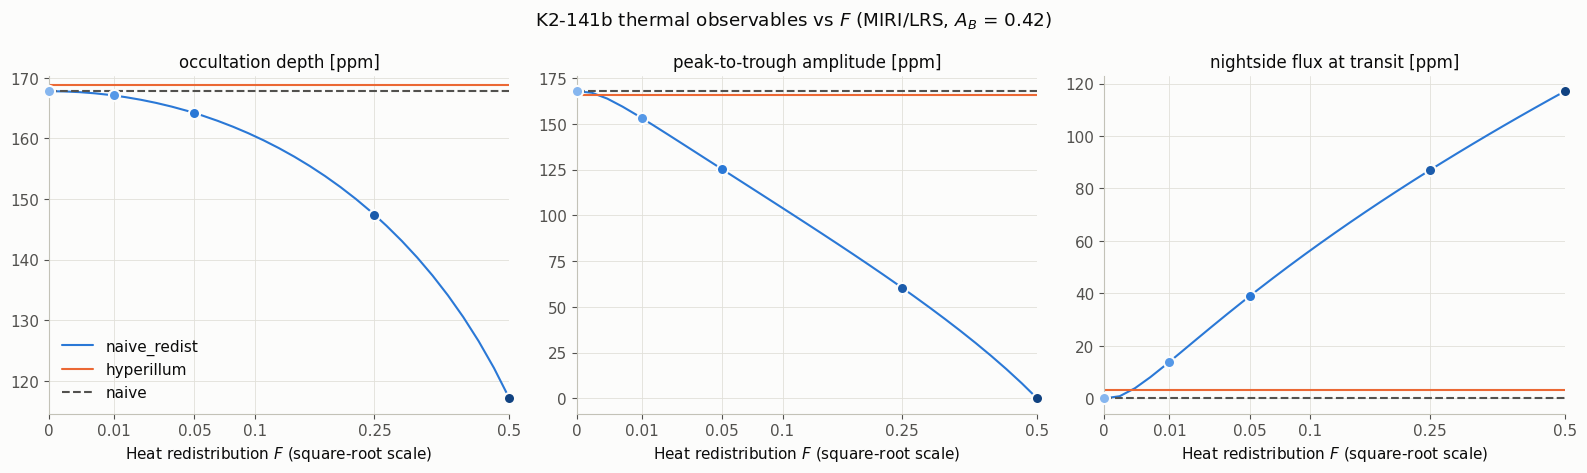

In [12]:
F_grid = np.unique(np.concatenate([0.5 * np.linspace(0., 1., 31)**2, F_values]))   # dense at small F
obs = pmap(thermal_curves, [("naive_redist", F) for F in F_grid])
series = {"occultation depth [ppm]": lambda o: o[2],
          "peak-to-trough amplitude [ppm]": lambda o: np.ptp(o[1]),
          "nightside flux at transit [ppm]": lambda o: o[1][0]}

fig, axs = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, get) in zip(axs, series.items()):
    ax.plot(F_grid, [get(o) for o in obs], color=C_REDIST, label="naive_redist")
    for F, col in zip(F_values, F_COLORS):
        ax.plot(F, get(redist[F]), "o", ms=8, color=col, mec="#fcfcfb", mew=1.5, zorder=4, clip_on=False)
    ax.axhline(get(ref["hyperillum"]), color=C_HI, label="hyperillum")
    ax.axhline(get(ref["naive"]), color=C_NAIVE, ls="--", label="naive")
    ax.set_title(name)
    sqrt_F_axis(ax)
axs[0].legend(loc="lower left")
fig.suptitle(f"K2-141b thermal observables vs $F$ ({Instrument}, $A_B$ = {A_B:.2f})")
plt.tight_layout()
plt.show()

### 6.2 Degeneracy: which `naive_redist` mimics hyperillumination?

This fit uses a noiseless `hyperillum` truth ($A_B = 0.42$, no redistribution), binned like `FittingConfig`: 27 bins per orbit, 3 orbits, 323 ppm/min for MIRI/LRS. `naive_redist` is fitted to it through `model_pcurve`, over $(A_B, F)$ and with a free offset. As in `simple_bias_analysis`, $\chi^2$ is the squared distance between the two noiseless models, in units of the per-bin noise. Only the thermal part is used, since the transit cancels and the reflected part is kept out here. The contours mark $\Delta\chi^2 = 2.30$ and $6.18$ above the minimum. Inside them, a 3-orbit observation could not tell a model apart from the best fit at 68 % and 95 %.

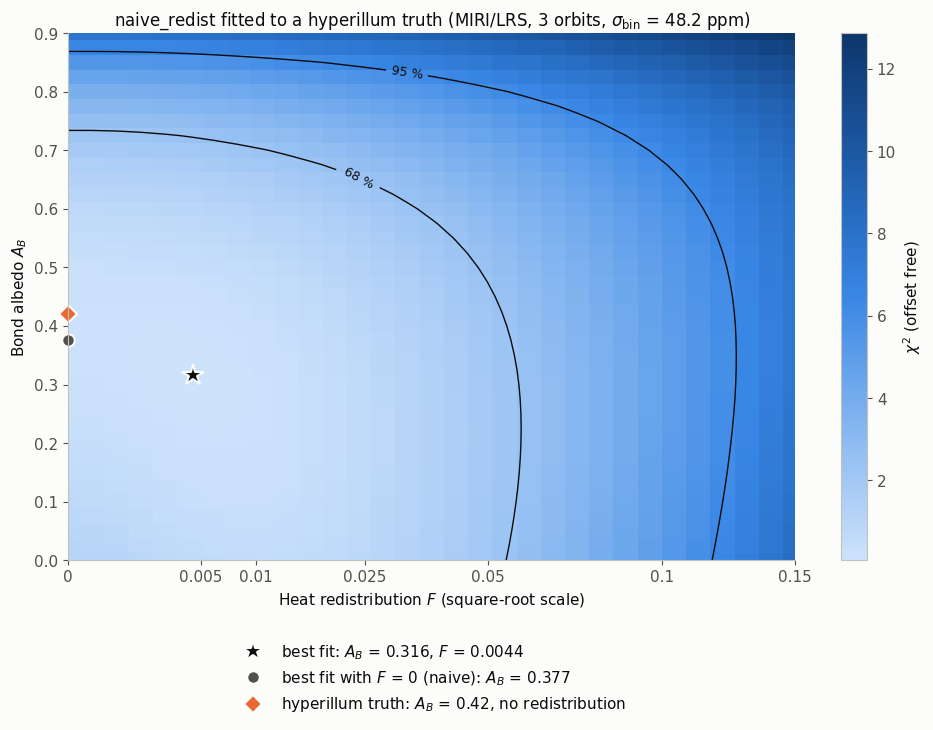

68 % region on the grid: F <= 0.054,  A_B in [0.000, 0.725]


,A_B,F,T_night (eq. 1) [K],chi2
fit,,,,
hyperillum truth,0.4200,0.0000,0.0000,0.0000
naive (F = 0),0.3768,0.0000,0.0000,0.1310
naive_redist,0.3160,0.0044,598.3076,0.0602


In [15]:
with contextlib.redirect_stdout(io.StringIO()):   # mute "no stellar models provided, using blackbody approximation"
    stellar_grid = sp.stellar_grid.gen_grid(lambda_range[0], lambda_range[1], logg=4.5, response=filter_path)
cfg = FittingConfig(planet=K2_141b, stellar_grid=stellar_grid, filter_path=filter_path, l1=lambda_range[0], l2=lambda_range[1],
                    A_=ScaledBandAlbedo(1.), u_B=u_B, u=u, reflected=False, transit=False)   # thermal only
truth = binned(cfg, model_pcurve(cfg, "hyperillum", A_B)[1])   # noiseless hyperillumination "data" [ppm]

def chi2(A_B_, F):
    # squared distance naive_redist(A_B_, F) - truth in units of sigma_bin, constant offset free (as in simple_bias_analysis.fit_naive)
    r = truth - binned(cfg, model_pcurve(cfg, "naive_redist", A_B_, F=F)[1])
    return float(np.sum(((r - r.mean()) / cfg.sigma_bin) ** 2))

F_MAX, A_B_MAX = 0.15, 0.9
AB_grid = np.linspace(0., A_B_MAX, 37)
F_fit_grid = F_MAX * np.linspace(0., 1., 31)**2   # uniform on the square-root axis
X2 = np.array(pmap(chi2, [(a, f) for a in AB_grid for f in F_fit_grid])).reshape(len(AB_grid), len(F_fit_grid))

# refine from the best grid cell (sequential optimisers cannot be parallelised); F = 0 is the plain naive fit
i, j = np.unravel_index(np.argmin(X2), X2.shape)
fit = minimize(lambda p: chi2(*p), x0=[AB_grid[i], F_fit_grid[j]], method="Nelder-Mead", bounds=[(0., A_B_MAX), (0., 0.5)], options=dict(xatol=1e-4, fatol=1e-6))
fit0 = minimize_scalar(lambda a: chi2(a, 0.), bounds=(0., A_B_MAX), method="bounded", options=dict(xatol=1e-4))
A_B_fit, F_fit = fit.x

# cell edges halfway between grid points, clipped to the grid range (F in square-root space, where the grid is uniform)
edges = lambda x, lo, hi: np.concatenate([[lo], 0.5 * (x[1:] + x[:-1]), [hi]])
F_edges = edges(np.sqrt(F_fit_grid), 0., np.sqrt(F_MAX))**2
AB_edges = edges(AB_grid, 0., A_B_MAX)

fig, ax = plt.subplots(figsize=(10, 7.5))
im = ax.pcolormesh(F_edges, AB_edges, X2, cmap=SEQ_BLUE, shading="flat", rasterized=True)
cs = ax.contour(F_fit_grid, AB_grid, X2 - fit.fun, levels=[2.30, 6.18], colors=INK, linewidths=1.0)
ax.clabel(cs, fmt={2.30: "68 %", 6.18: "95 %"}, fontsize=9)
ax.plot(F_fit, A_B_fit, "*", ms=16, color=INK, mec="#fcfcfb", mew=1.5, label=f"best fit: $A_B$ = {A_B_fit:.3f}, $F$ = {F_fit:.4f}")
ax.plot(0., fit0.x, "o", ms=9, color=C_NAIVE, mec="#fcfcfb", mew=1.5, clip_on=False, label=f"best fit with $F$ = 0 (naive): $A_B$ = {fit0.x:.3f}")
ax.plot(0., A_B, "D", ms=9, color=C_HI, mec="#fcfcfb", mew=1.5, clip_on=False, label=f"hyperillum truth: $A_B$ = {A_B:.2f}, no redistribution")
ax.grid(False)
sqrt_F_axis(ax, F_max=F_MAX, ticks=(0., 0.005, 0.01, 0.025, 0.05, 0.1, 0.15))
ax.set(ylabel="Bond albedo $A_B$", ylim=(0., A_B_MAX),
       title=f"naive_redist fitted to a hyperillum truth ({Instrument}, {cfg.n_orbits} orbits, $\\sigma_\\mathrm{{bin}}$ = {cfg.sigma_bin:.1f} ppm)")
fig.colorbar(im, ax=ax, label="$\\chi^2$ (offset free)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=1)
plt.tight_layout()
plt.show()

inside = X2 - fit.fun < 2.30
print(f"68 % region on the grid: F <= {F_fit_grid[inside.any(axis=0)].max():.3f},  A_B in [{AB_grid[inside.any(axis=1)].min():.3f}, {AB_grid[inside.any(axis=1)].max():.3f}]")

pd.DataFrame([
    {"fit": "hyperillum truth", "A_B": A_B, "F": 0., "T_night (eq. 1) [K]": 0., "chi2": 0.},
    {"fit": "naive (F = 0)", "A_B": fit0.x, "F": 0., "T_night (eq. 1) [K]": 0., "chi2": fit0.fun},
    {"fit": "naive_redist", "A_B": A_B_fit, "F": F_fit, "T_night (eq. 1) [K]": float(surface_temperature(np.pi, K2_141b, "naive_redist", A_B=A_B_fit, F=F_fit)), "chi2": fit.fun},
]).set_index("fit").round(4)